In [1]:
from pathlib import Path

PROJECT = Path("/kaggle/working/vlm_blip_hallucination")

for folder in [
    "configs",
    "outputs",
    "scratch",
]:
    (PROJECT / folder).mkdir(parents=True, exist_ok=True)

print(PROJECT)

/kaggle/working/vlm_blip_hallucination


In [2]:
!pip install -q transformers accelerate datasets pillow pycocotools

In [3]:
# Verify GPU environment
import torch
import sys

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Device Name:", torch.cuda.get_device_name(0))
    print("Total Memory:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GiB")
    !nvidia-smi
else:
    print("WARNING: CUDA is not available. Running on CPU will be slow.")


Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch version: 2.11.0+cu128
CUDA available: True
Device Name: Tesla T4
Total Memory: 14.56 GiB
Tue Oct 20 05:56:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             10W /   70W |       3MiB /  15360MiB |

In [4]:
# Install / upgrade required packages
%pip install -U transformers accelerate pillow nltk


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 96.5 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 100.3 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 72.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 40.0 MB/s eta 0:00:00
  Attempting uninstall: pillow
    Found existing installation: pillow 12.3.0
    Uninstalling pillow-12.3.0:
      Successfully uninstalled pillow-12.3.0
  Attempting uninstall: nltk
    Found existing installation: nltk 3.9.1
    Uninstalling nltk-3.9.1:
      Successfully uninstalled nltk-3.9.1
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.29.0
    Uninstalling huggingface_hub-1.29.0:
      Successfully uninstalled huggingface_hub-1.29.0
  Attempting uninstall: transformers
    Found existing installation: transformers 5.16.1
    

In [ ]:
import os
import gc
import torch
import shutil
from pathlib import Path
from huggingface_hub import snapshot_download, login
from transformers import AutoProcessor, Blip2ForConditionalGeneration

# 1. Provide your HF Token (Replace with your actual token or Kaggle User Secret)
# Get a free read token at: https://huggingface.co/settings/tokens
HF_TOKEN = "" 

# If you stored it in Kaggle Secrets:
try:
    from kaggle_secrets import UserSecretsClient
    user_secrets = UserSecretsClient()
    HF_TOKEN = user_secrets.get_secret("HF_TOKEN")
except Exception:
    pass

if HF_TOKEN and HF_TOKEN != "hf_your_token_here":
    os.environ["HF_TOKEN"] = HF_TOKEN
    login(token=HF_TOKEN, add_to_git_credential=False)
    print("✓ Successfully authenticated with Hugging Face Hub.")
else:
    print("⚠ Warning: No HF token provided. Using unauthenticated download.")

# 2. Free up GPU memory from any previous failed loads
if "model" in globals():
    del model
gc.collect()
torch.cuda.empty_cache()

MODEL_ID = "Salesforce/blip2-opt-2.7b"
device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if torch.cuda.is_available() else torch.float32

# 3. Download the full snapshot with retries to prevent connection drops
print(f"Downloading/verifying weights for {MODEL_ID} with retries...")
try:
    model_dir = snapshot_download(
        repo_id=MODEL_ID,
        max_workers=4,
        resume_download=True,
        token=HF_TOKEN if HF_TOKEN != "hf_your_token_here" else None
    )
    print(f"✓ Weights cached locally at: {model_dir}")
except Exception as e:
    print(f"Direct download hit an issue: {e}\nRetrying with single-thread download...")
    model_dir = snapshot_download(
        repo_id=MODEL_ID,
        max_workers=1,
        resume_download=True,
        token=HF_TOKEN if HF_TOKEN != "hf_your_token_here" else None
    )

# 4. Load from local cache into GPU
print(f"Loading {MODEL_ID} into {device} ({dtype})...")
processor = AutoProcessor.from_pretrained(model_dir)

# Set left-padding for batched inference on OPT
processor.tokenizer.padding_side = "left"
if processor.tokenizer.pad_token is None:
    processor.tokenizer.pad_token = processor.tokenizer.eos_token

model = Blip2ForConditionalGeneration.from_pretrained(
    model_dir,
    torch_dtype=dtype,
    low_cpu_mem_usage=True
).to(device)
model.eval()

vram_gb = torch.cuda.memory_allocated() / 1024**3
print("=" * 60)
print(f"SUCCESS: {MODEL_ID} is fully loaded!")
print(f"GPU VRAM Allocated: {vram_gb:.2f} GiB / 15.0 GiB")
print("=" * 60)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


✓ Successfully authenticated with Hugging Face Hub.
Downloading/verifying weights for Salesforce/blip2-opt-2.7b with retries...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:190: UserWarning: The `resume_download` argument is deprecated and ignored in `snapshot_download`. Downloads always resume whenever possible.
  warnings.warn(


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

✓ Weights cached locally at: /root/.cache/huggingface/hub/models--Salesforce--blip2-opt-2.7b/snapshots/59a1ef6c1e5117b3f65523d1c6066825bcf315e3
Loading Salesforce/blip2-opt-2.7b into cuda (torch.float16)...


Loading weights:   0%|          | 0/1247 [00:00<?, ?it/s]

SUCCESS: Salesforce/blip2-opt-2.7b is fully loaded!
GPU VRAM Allocated: 7.19 GiB / 15.0 GiB


In [6]:
import os

os.makedirs("/kaggle/working/coco", exist_ok=True)

!wget -P /kaggle/working/coco \
http://images.cocodataset.org/zips/val2017.zip

--2026-10-20 06:00:32--  http://images.cocodataset.org/zips/val2017.zip
Resolving images.cocodataset.org (images.cocodataset.org)... 16.182.100.234, 16.15.156.149, 16.15.253.3, ...
Connecting to images.cocodataset.org (images.cocodataset.org)|16.182.100.234|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 815585330 (778M) [application/zip]
Saving to: ‘/kaggle/working/coco/val2017.zip’

val2017.zip         100%[===================>] 777.80M  95.0MB/s    in 8.1s    

2026-10-20 06:00:40 (95.6 MB/s) - ‘/kaggle/working/coco/val2017.zip’ saved [815585330/815585330]



In [7]:
!wget -P /kaggle/working/coco \
http://images.cocodataset.org/annotations/annotations_trainval2017.zip

--2026-10-20 06:00:41--  http://images.cocodataset.org/annotations/annotations_trainval2017.zip
Resolving images.cocodataset.org (images.cocodataset.org)... 16.15.207.51, 16.15.246.20, 16.15.214.46, ...
Connecting to images.cocodataset.org (images.cocodataset.org)|16.15.207.51|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 252907541 (241M) [application/zip]
Saving to: ‘/kaggle/working/coco/annotations_trainval2017.zip’

annotations_trainva 100%[===================>] 241.19M  96.7MB/s    in 2.5s    

2026-10-20 06:00:43 (96.7 MB/s) - ‘/kaggle/working/coco/annotations_trainval2017.zip’ saved [252907541/252907541]



In [8]:
!unzip -q /kaggle/working/coco/val2017.zip \
-d /kaggle/working/coco/

!unzip -q \
/kaggle/working/coco/annotations_trainval2017.zip \
-d /kaggle/working/coco/

In [9]:
from pathlib import Path

COCO_IMG_DIR = Path("/kaggle/working/coco/val2017")

ANN_DIR = Path("/kaggle/working/coco/annotations")

INST_PATH = ANN_DIR / "instances_val2017.json"

CAPT_PATH = ANN_DIR / "captions_val2017.json"

In [10]:
print(COCO_IMG_DIR.exists())
print(ANN_DIR.exists())
print(INST_PATH.exists())
print(CAPT_PATH.exists())

True
True
True
True


In [11]:
import json
import random

# Configuration
SEED = 42
SAMPLE_SIZE = 200

MANIFEST_PATH = PROJECT / "configs" / "coco_val2017_pilot_200_manifest.json"

# Load annotations
with open(INST_PATH, "r", encoding="utf-8") as f:
    instances = json.load(f)

with open(CAPT_PATH, "r", encoding="utf-8") as f:
    captions = json.load(f)

# Build lookup tables
inst_imgs = {img["id"]: img for img in instances["images"]}
capt_imgs = {img["id"]: img for img in captions["images"]}

# Keep only images present in both annotation files
common_ids = sorted(set(inst_imgs.keys()) & set(capt_imgs.keys()))

print(f"Total validation images: {len(common_ids)}")

# Reproducible sampling
rng = random.Random(SEED)
selected_ids = sorted(rng.sample(common_ids, SAMPLE_SIZE))

manifest_rows = []

for img_id in selected_ids:
    img = inst_imgs[img_id]

    manifest_rows.append({
        "image_id": img_id,
        "file_name": img["file_name"],
        "width": img["width"],
        "height": img["height"]
    })

manifest = {
    "dataset": "COCO 2017",
    "split": "val2017",
    "seed": SEED,
    "sample_size": SAMPLE_SIZE,
    "images": manifest_rows
}

with open(MANIFEST_PATH, "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2)

print(f"Saved manifest to:")
print(MANIFEST_PATH)
print(f"Number of sampled images: {len(manifest_rows)}")

Total validation images: 5000
Saved manifest to:
/kaggle/working/vlm_blip_hallucination/configs/coco_val2017_pilot_200_manifest.json
Number of sampled images: 200


In [12]:
# ============================================================
#  Create 5,000-Image Full Manifest & 500-Image Subset Manifest
# ============================================================
import json
import random

SEED = 42
SUBSET_SIZE = 500

FULL_MANIFEST_PATH = PROJECT / "configs" / "coco_val2017_full_5000_manifest.json"
SUBSET_MANIFEST_PATH = PROJECT / "configs" / "coco_val2017_subset_500_manifest.json"

with open(INST_PATH, "r", encoding="utf-8") as f:
    instances = json.load(f)

with open(CAPT_PATH, "r", encoding="utf-8") as f:
    captions = json.load(f)

inst_imgs = {img["id"]: img for img in instances["images"]}
capt_imgs = {img["id"]: img for img in captions["images"]}

# Keep all validation images present in both annotation files (5,000 images)
common_ids = sorted(set(inst_imgs.keys()) & set(capt_imgs.keys()))
print(f"Total valid COCO val2017 images: {len(common_ids)}")

# 1. Full 5,000-image manifest (for CHAIR)
full_rows = [
    {
        "image_id": img_id,
        "file_name": inst_imgs[img_id]["file_name"],
        "width": inst_imgs[img_id]["width"],
        "height": inst_imgs[img_id]["height"]
    }
    for img_id in common_ids
]

full_manifest = {
    "dataset": "COCO 2017",
    "split": "val2017_full",
    "seed": SEED,
    "sample_size": len(full_rows),
    "images": full_rows
}

with open(FULL_MANIFEST_PATH, "w", encoding="utf-8") as f:
    json.dump(full_manifest, f, indent=2)

# 2. Reproducible 500-image subset manifest (for POPE, Brier, VCD, THRONE)
rng = random.Random(SEED)
subset_ids = sorted(rng.sample(common_ids, SUBSET_SIZE))
subset_rows = [
    {
        "image_id": img_id,
        "file_name": inst_imgs[img_id]["file_name"],
        "width": inst_imgs[img_id]["width"],
        "height": inst_imgs[img_id]["height"]
    }
    for img_id in subset_ids
]

subset_manifest = {
    "dataset": "COCO 2017",
    "split": "val2017_subset_500",
    "seed": SEED,
    "sample_size": len(subset_rows),
    "images": subset_rows
}

with open(SUBSET_MANIFEST_PATH, "w", encoding="utf-8") as f:
    json.dump(subset_manifest, f, indent=2)

# Point MANIFEST_PATH to SUBSET_MANIFEST_PATH for downstream POPE/THRONE stages
MANIFEST_PATH = SUBSET_MANIFEST_PATH

print(f"Saved Full Manifest ({len(full_rows)} imgs)   -> {FULL_MANIFEST_PATH}")
print(f"Saved Subset Manifest ({len(subset_rows)} imgs) -> {SUBSET_MANIFEST_PATH}")

Total valid COCO val2017 images: 5000
Saved Full Manifest (5000 imgs)   -> /kaggle/working/vlm_blip_hallucination/configs/coco_val2017_full_5000_manifest.json
Saved Subset Manifest (500 imgs) -> /kaggle/working/vlm_blip_hallucination/configs/coco_val2017_subset_500_manifest.json


In [13]:
# ============================================================
#  Fast Batched BLIP-2 Caption Generation (5,000 Images)
# ============================================================
import json
from pathlib import Path
from PIL import Image, ImageFile
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import logging
from tqdm.auto import tqdm

ImageFile.LOAD_TRUNCATED_IMAGES = True
logging.set_verbosity_error()

CAPTION_OUT = PROJECT / "outputs/captions/blip_full_5000.jsonl"
CAPTION_OUT.parent.mkdir(parents=True, exist_ok=True)

with open(FULL_MANIFEST_PATH, "r", encoding="utf-8") as f:
    full_manifest = json.load(f)

class COCOCaptionDataset(Dataset):
    def __init__(self, image_rows, img_dir):
        self.rows = image_rows
        self.img_dir = Path(img_dir)

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        row = self.rows[idx]
        img_path = self.img_dir / row["file_name"]
        image = Image.open(img_path).convert("RGB")
        return image, row["image_id"], row["file_name"]

def collate_pil(batch):
    images, img_ids, file_names = zip(*batch)
    return list(images), list(img_ids), list(file_names)

BATCH_SIZE = 64
dataset = COCOCaptionDataset(full_manifest["images"], COCO_IMG_DIR)
loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_pil,
    pin_memory=True
)

caption_records = []
print(f"Generating captions for {len(dataset)} images (batch_size={BATCH_SIZE})...")

with open(CAPTION_OUT, "w", encoding="utf-8") as fout:
    for batch_imgs, batch_ids, batch_files in tqdm(loader, desc="Captioning 5000 imgs"):
        inputs = processor(images=batch_imgs, return_tensors="pt").to(device, dtype)
        
        with torch.inference_mode():
            out_ids = model.generate(**inputs, max_new_tokens=50, do_sample=False)
        
        captions_batch = processor.batch_decode(out_ids, skip_special_tokens=True)
        
        for img_id, fname, cap in zip(batch_ids, batch_files, captions_batch):
            record = {
                "image_id": int(img_id),
                "file_name": fname,
                "model": MODEL_ID,
                "caption": cap.strip()
            }
            caption_records.append(record)
            fout.write(json.dumps(record, ensure_ascii=False) + "\n")

print(f"\nSuccessfully generated {len(caption_records)} captions -> {CAPTION_OUT}")
for sample_rec in caption_records[:3]:
    print(f"  [{sample_rec['file_name']}] -> {sample_rec['caption']}")

Generating captions for 5000 images (batch_size=64)...


Captioning 5000 imgs:   0%|          | 0/79 [00:00<?, ?it/s]


Successfully generated 5000 captions -> /kaggle/working/vlm_blip_hallucination/outputs/captions/blip_full_5000.jsonl
  [000000000139.jpg] -> a living room with a fireplace and a table
  [000000000285.jpg] -> a brown bear sitting in the grass
  [000000000632.jpg] -> a bedroom with a bed, a dresser, a bookcase and a window


## Stage 6: BLIP Caption Generation & Publication-Grade CHAIR

We generate descriptive captions across all 200 pilot images. Then, we evaluate **CHAIR** (**C**aption **H**allucination **A**ssessment with **I**mage **R**elevance).

### Enhancements in this CHAIR Implementation
* **Compound Category Matching**: Detects multi-word COCO categories (`cell phone`, `fire hydrant`, `traffic light`, `sports ball`, `dining table`, `hot dog`).
* **Morphological Lemmatization**: Uses `nltk.stem.WordNetLemmatizer` for accurate plural handling.
* **Negation Filtering**: Discards objects preceded by `"no"`, `"not"`, `"without"`, `"lacking"`.
* Metrics Computed:
  $$\text{CHAIR}_i = \frac{\text{Hallucinated Objects}}{\text{Total Predicted Objects}}, \quad \text{CHAIR}_s = \frac{\text{Sentences with } \ge 1 \text{ Hallucination}}{\text{Total Sentences}}$$


In [14]:
# ============================================================
# CHAIR Evaluation (5,000 Images)
# Compares Naive 1-gram vs. Enhanced Compound/Synonym/Negation CHAIR
# ============================================================
import os
import re
import json
import nltk
from nltk.stem import WordNetLemmatizer

os.environ["NLTK_ALLOW_PROXIED_URLOPEN"] = "1"
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

lemmatizer = WordNetLemmatizer()

cat_id_to_name = {c["id"]: c["name"] for c in instances["categories"]}
coco_vocab = set(cat_id_to_name.values())

SYNONYM_MAP = {
    "people": "person", "men": "person", "man": "person", "women": "person",
    "woman": "person", "child": "person", "children": "person", "boy": "person",
    "girl": "person", "player": "person", "guy": "person", "kid": "person",
    "skateboarder": "person", "surfer": "person", "skier": "person", "snowboarder": "person",
    "plane": "airplane", "aeroplane": "airplane", "jet": "airplane",
    "bike": "bicycle", "dirtbike": "motorcycle", "motorbike": "motorcycle",
    "auto": "car", "taxi": "car", "cab": "car", "suv": "car", "van": "car",
    "bus": "bus", "minibus": "bus",
    "kitty": "cat", "kitten": "cat", "feline": "cat",
    "puppy": "dog", "pup": "dog", "canine": "dog",
    "calf": "cow", "foal": "horse", "pony": "horse",
    "sofa": "couch", "settee": "couch",
    "monitor": "tv", "screen": "tv", "television": "tv",
    "pc": "laptop", "macbook": "laptop",
    "cellphone": "cell phone", "mobile": "cell phone",
    "fridge": "refrigerator",
    "mug": "cup", "glass": "cup",
    "flatware": "fork", "silverware": "fork",
    "dish": "bowl"
}

NEGATION_WORDS = {"no", "not", "without", "lacking", "devoid", "none", "zero"}

def extract_naive_objects(text: str, vocab: set) -> set:
    """Baseline naive 1-gram lemmatized matching without synonyms or compound handling."""
    words = re.findall(r"[a-z0-9]+", text.lower())
    lemmas = [lemmatizer.lemmatize(w, pos="n") for w in words]
    return {w for w in lemmas if w in vocab}

def extract_grounded_objects(text: str, vocab: set) -> set:
    """Enhanced parser: Synonym mapping + 3/2/1-gram compounds + negation window."""
    words = re.findall(r"[a-z0-9]+", text.lower())
    lemmas = [lemmatizer.lemmatize(SYNONYM_MAP.get(w, w), pos="n") for w in words]
    
    detected = set()
    n = len(lemmas)
    skip_indices = set()
    
    for i in range(n):
        if i in skip_indices:
            continue
        window_start = max(0, i - 3)
        if set(words[window_start:i]) & NEGATION_WORDS:
            continue
        if i + 2 < n:
            g3 = f"{lemmas[i]} {lemmas[i+1]} {lemmas[i+2]}"
            if g3 in vocab:
                detected.add(g3)
                skip_indices.update([i, i+1, i+2])
                continue
        if i + 1 < n:
            g2 = f"{lemmas[i]} {lemmas[i+1]}"
            if g2 in vocab:
                detected.add(g2)
                skip_indices.update([i, i+1])
                continue
        if lemmas[i] in vocab:
            detected.add(lemmas[i])
    return detected

# Build Ground Truth (Instances + Reference Captions per Rohrbach et al., 2018)
gt_map_naive = {}
gt_map = {}

for ann in instances["annotations"]:
    img_id = int(ann["image_id"])
    cname = cat_id_to_name[int(ann["category_id"])]
    gt_map_naive.setdefault(img_id, set()).add(cname)
    gt_map.setdefault(img_id, set()).add(cname)

if "annotations" in captions:
    for ann in captions["annotations"]:
        img_id = int(ann["image_id"])
        ctext = ann["caption"]
        gt_map_naive.setdefault(img_id, set()).update(extract_naive_objects(ctext, coco_vocab))
        gt_map.setdefault(img_id, set()).update(extract_grounded_objects(ctext, coco_vocab))

def evaluate_chair(records, extractor_fn, gt_dict):
    chair_details = []
    for row in records:
        img_id = row["image_id"]
        gt = gt_dict.get(img_id, set())
        predicted = extractor_fn(row["caption"], coco_vocab)
        hallucinated = sorted(predicted - gt)
        omitted = sorted(gt - predicted)
        chair_details.append({
            "image_id": img_id,
            "caption": row["caption"],
            "gt": sorted(gt),
            "predicted": sorted(predicted),
            "hallucinated": hallucinated,
            "omitted": omitted,
            "num_pred": len(predicted),
            "num_hall": len(hallucinated),
            "num_omit": len(omitted)
        })
    tot_pred = sum(r["num_pred"] for r in chair_details)
    tot_hall = sum(r["num_hall"] for r in chair_details)
    tot_omit = sum(r["num_omit"] for r in chair_details)
    tot_gt = sum(len(r["gt"]) for r in chair_details)
    sent_hall = sum(1 for r in chair_details if r["num_hall"] > 0)
    
    summary = {
        "num_images": len(chair_details),
        "total_predicted_objects": tot_pred,
        "total_hallucinated_objects": tot_hall,
        "chair_i": round(tot_hall / tot_pred, 4) if tot_pred else 0.0,
        "chair_s": round(sent_hall / len(chair_details), 4) if chair_details else 0.0,
        "omission_rate": round(tot_omit / tot_gt, 4) if tot_gt else 0.0
    }
    return summary, chair_details

naive_summary, _ = evaluate_chair(caption_records, extract_naive_objects, gt_map_naive)
chair_summary, chair_records = evaluate_chair(caption_records, extract_grounded_objects, gt_map)

CHAIR_OUT = PROJECT / "outputs/metrics/blip_chair_metrics_5000.json"
CHAIR_OUT.parent.mkdir(parents=True, exist_ok=True)
with open(CHAIR_OUT, "w", encoding="utf-8") as f:
    json.dump({
        "model": MODEL_ID,
        "naive_summary": naive_summary,
        "enhanced_summary": chair_summary,
        "details": chair_records
    }, f, indent=2)

print("=" * 68)
print(f"CHAIR BENCHMARK ABLATION ON 5,000 IMAGES ({MODEL_ID})")
print("=" * 68)
print(f"{'Parser Variant':28s} | {'CHAIR-i (%)':>11s} | {'CHAIR-s (%)':>11s} | {'Omission (%)':>12s}")
print("-" * 68)
print(f"{'Naive 1-gram (No Synonyms)':28s} | {naive_summary['chair_i']*100:10.2f}% | {naive_summary['chair_s']*100:10.2f}% | {naive_summary['omission_rate']*100:11.2f}%")
print(f"{'Enhanced (Synonyms+N-grams)':28s} | {chair_summary['chair_i']*100:10.2f}% | {chair_summary['chair_s']*100:10.2f}% | {chair_summary['omission_rate']*100:11.2f}%")
print("=" * 68)

CHAIR BENCHMARK ABLATION ON 5,000 IMAGES (Salesforce/blip2-opt-2.7b)
Parser Variant               | CHAIR-i (%) | CHAIR-s (%) | Omission (%)
--------------------------------------------------------------------
Naive 1-gram (No Synonyms)   |       2.72% |       2.22% |       73.95%
Enhanced (Synonyms+N-grams)  |       2.06% |       2.66% |       59.16%


Proper Tokenization over Regex

# Stage POPE

In [15]:
# ============================================================
# Construct Official POPE Benchmark (500-Image Subset, k=3)
# ============================================================
from collections import defaultdict, Counter
import random
import json

POPE_FILE = PROJECT / "configs/pope_blip2_splits_500.jsonl"

# 1. Build global object frequency & co-occurrence matrix across all 5,000 COCO images
co_occur = defaultdict(Counter)
global_freq = Counter()

for img_id, objs in gt_map.items():
    global_freq.update(objs)
    for o1 in objs:
        for o2 in objs:
            if o1 != o2:
                co_occur[o1][o2] += 1

all_categories = sorted(coco_vocab)
# Rank all 80 classes by global frequency for Popular negative sampling
popular_ranked = [c for c, _ in global_freq.most_common()]

with open(SUBSET_MANIFEST_PATH, "r", encoding="utf-8") as f:
    subset_manifest = json.load(f)

rng = random.Random(42)
pope_questions = []
used_images = 0
K_SAMPLES = 3  # Official POPE spec: 3 positives + 3 negatives per image per split

for row in subset_manifest["images"]:
    image_id = row["image_id"]
    present = sorted(gt_map.get(image_id, set()))
    if len(present) == 0:
        continue

    present_set = set(present)
    absent = [c for c in all_categories if c not in present_set]
    k = min(K_SAMPLES, len(present), len(absent))
    if k == 0:
        continue

    used_images += 1

    # Sample k positive objects
    pos_objs = rng.sample(present, k)

    # 1. Random negatives: k random absent objects
    rand_negs = rng.sample(absent, k)

    # 2. Popular negatives: top-k most frequent absent objects globally
    pop_negs = [c for c in popular_ranked if c not in present_set][:k]

    # 3. Adversarial negatives: top-k absent objects ranked by co-occurrence with present objects
    adv_scores = Counter()
    for obj in present:
        adv_scores.update(co_occur[obj])
    for obj in present:
        adv_scores.pop(obj, None)
    
    adv_negs = [c for c, _ in adv_scores.most_common() if c not in present_set][:k]
    # Fallback to popular/random if co-occurrence list has fewer than k items
    if len(adv_negs) < k:
        for c in pop_negs + rand_negs:
            if c not in adv_negs:
                adv_negs.append(c)
            if len(adv_negs) == k:
                break

    split_negatives = {
        "random": rand_negs,
        "popular": pop_negs,
        "adversarial": adv_negs
    }

    for split_name, neg_list in split_negatives.items():
        for pos_obj, neg_obj in zip(pos_objs, neg_list):
            pope_questions.append({
                "split": split_name,
                "image_id": image_id,
                "object": pos_obj,
                "question": f"Is there a {pos_obj} in the image?",
                "answer": "yes"
            })
            pope_questions.append({
                "split": split_name,
                "image_id": image_id,
                "object": neg_obj,
                "question": f"Is there a {neg_obj} in the image?",
                "answer": "no"
            })

with open(POPE_FILE, "w", encoding="utf-8") as f:
    for q in pope_questions:
        f.write(json.dumps(q) + "\n")

print("=" * 60)
print(f"POPE Benchmark Constructed (k={K_SAMPLES} per image)")
print(f"Images used       : {used_images}")
print(f"Total questions   : {len(pope_questions)} ({len(pope_questions)//3} per split)")
print(f"Saved to          : {POPE_FILE}")
print("=" * 60)

POPE Benchmark Constructed (k=3 per image)
Images used       : 494
Total questions   : 7026 (2342 per split)
Saved to          : /kaggle/working/vlm_blip_hallucination/configs/pope_blip2_splits_500.jsonl


In [ ]:
# ============================================================
# Batched POPE Evaluation + Logit Calibration & Brier Score
# Deduplicates queries and computes POPE + Brier in a SINGLE pass!
# ============================================================
import json
import torch
import numpy as np
from PIL import Image
from collections import Counter
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

POPE_OUT = PROJECT / "outputs/metrics/blip_pope_results.json"
CONFIDENCE_OUT = PROJECT / "outputs/metrics/blip_brier_scores.json"

with open(SUBSET_MANIFEST_PATH, "r", encoding="utf-8") as f:
    subset_manifest = json.load(f)
image_lookup = {img["image_id"]: img["file_name"] for img in subset_manifest["images"]}

# 1. Extract token IDs for "Yes" and "No" variants for calibrated Brier scoring
yes_token_ids = list({processor.tokenizer(s, add_special_tokens=False).input_ids[-1] for s in ["yes", "Yes", " yes", " Yes"]})
no_token_ids = list({processor.tokenizer(s, add_special_tokens=False).input_ids[-1] for s in ["no", "No", " no", " No"]})
print(f"Yes Token IDs: {yes_token_ids} | No Token IDs: {no_token_ids}")

# 2. Deduplicate (image_id, question) pairs so we don't run the same positive query 3 times
unique_queries = {}
for q in pope_questions:
    key = (q["image_id"], q["question"])
    if key not in unique_queries:
        unique_queries[key] = {
            "image_id": q["image_id"],
            "file_name": image_lookup[q["image_id"]],
            "question": q["question"]
        }

unique_query_list = list(unique_queries.values())
print(f"Total POPE questions: {len(pope_questions)} -> Unique VLM queries to run: {len(unique_query_list)}")

class POPEQueryDataset(Dataset):
    def __init__(self, queries, img_dir):
        self.queries = queries
        self.img_dir = img_dir

    def __len__(self):
        return len(self.queries)

    def __getitem__(self, idx):
        item = self.queries[idx]
        image = Image.open(self.img_dir / item["file_name"]).convert("RGB")
        prompt = f"Question: {item['question']} Answer:"
        return image, prompt, item["image_id"], item["question"]

def collate_pope(batch):
    images, prompts, img_ids, questions = zip(*batch)
    return list(images), list(prompts), list(img_ids), list(questions)

BATCH_SIZE = 64
pope_loader = DataLoader(
    POPEQueryDataset(unique_query_list, COCO_IMG_DIR),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_pope,
    pin_memory=True
)

# 3. Batched Inference Extracting Both Text Prediction & First-Token Logit Probabilities
query_cache = {}

for batch_imgs, batch_prompts, batch_ids, batch_qs in tqdm(pope_loader, desc="Running Batched POPE+Brier"):
    inputs = processor(
        images=batch_imgs,
        text=batch_prompts,
        return_tensors="pt",
        padding=True
    ).to(device, dtype)
    
    input_len = inputs["input_ids"].shape[1]

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=4,
            do_sample=False,
            return_dict_in_generate=True,
            output_scores=True
        )

    # Slice off echoed prompt tokens (Fixes Bug 4!)
    new_tokens = outputs.sequences[:, input_len:]
    decoded_answers = processor.batch_decode(new_tokens, skip_special_tokens=True)

    # First generated token logits for Brier Score calibration
    first_step_probs = torch.softmax(outputs.scores[0].float(), dim=-1)

    for i, (img_id, q_text, raw_ans) in enumerate(zip(batch_ids, batch_qs, decoded_answers)):
        clean_ans = raw_ans.strip().lower()
        if "yes" in clean_ans:
            pred = "yes"
        elif "no" in clean_ans:
            pred = "no"
        else:
            pred = "unknown"

        probs_i = first_step_probs[i]
        p_yes = sum(probs_i[tid].item() for tid in yes_token_ids)
        p_no = sum(probs_i[tid].item() for tid in no_token_ids)
        calibrated_p_yes = p_yes / (p_yes + p_no + 1e-8)

        query_cache[(int(img_id), q_text)] = {
            "raw_response": clean_ans,
            "prediction": pred,
            "raw_p_yes": p_yes,
            "raw_p_no": p_no,
            "calibrated_p_yes": calibrated_p_yes
        }

# 4. Aggregate Metrics Across Splits
split_stats = {
    "random": {"tp": 0, "tn": 0, "fp": 0, "fn": 0, "brier": []},
    "popular": {"tp": 0, "tn": 0, "fp": 0, "fn": 0, "brier": []},
    "adversarial": {"tp": 0, "tn": 0, "fp": 0, "fn": 0, "brier": []}
}

pope_eval_records = []
brier_records = []

for q in pope_questions:
    key = (q["image_id"], q["question"])
    res = query_cache[key]
    gt = q["answer"]
    pred = res["prediction"]
    split = q["split"]

    gt_binary = 1.0 if gt == "yes" else 0.0
    inst_brier = (res["calibrated_p_yes"] - gt_binary) ** 2
    split_stats[split]["brier"].append(inst_brier)

    if gt == "yes":
        if pred == "yes":
            split_stats[split]["tp"] += 1
        else:
            split_stats[split]["fn"] += 1
    else:
        if pred == "yes":
            split_stats[split]["fp"] += 1
        elif pred == "no":
            split_stats[split]["tn"] += 1

    pope_eval_records.append({
        "image_id": q["image_id"],
        "split": split,
        "object": q["object"],
        "question": q["question"],
        "ground_truth": gt,
        "raw_response": res["raw_response"],
        "prediction": pred,
        "correct": pred == gt,
        "calibrated_p_yes": round(res["calibrated_p_yes"], 4),
        "brier_score": round(inst_brier, 4)
    })
    brier_records.append(pope_eval_records[-1])

metrics_summary = {}
all_briers = []

for split, s in split_stats.items():
    tp, tn, fp, fn = s["tp"], s["tn"], s["fp"], s["fn"]
    total = tp + tn + fp + fn
    acc = (tp + tn) / total if total else 0.0
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = (2 * prec * rec / (prec + rec)) if (prec + rec) else 0.0
    yes_ratio = (tp + fp) / total if total else 0.0
    fpr = fp / (fp + tn) if (fp + tn) else 0.0
    mean_brier = float(np.mean(s["brier"])) if s["brier"] else 0.0
    all_briers.extend(s["brier"])

    metrics_summary[split] = {
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
        "yes_ratio": yes_ratio,
        "fpr": fpr,
        "brier_score": mean_brier
    }

overall_brier = float(np.mean(all_briers))

print("\n" + "=" * 92)
print(f"POPE QUANTITATIVE & CALIBRATION RESULTS : {MODEL_ID}")
print("=" * 92)
print(f"{'SPLIT':12s} | {'Accuracy':>8s} | {'Precision':>9s} | {'Recall':>8s} | {'F1 Score':>8s} | {'Yes (%)':>8s} | {'Brier':>7s}")
print("-" * 92)
for split, m in metrics_summary.items():
    print(
        f"{split.capitalize():12s}"
        f" | {m['accuracy']*100:7.2f}%"
        f" | {m['precision']*100:8.2f}%"
        f" | {m['recall']*100:7.2f}%"
        f" | {m['f1']*100:7.2f}%"
        f" | {m['yes_ratio']*100:7.2f}%"
        f" | {m['brier_score']:7.4f}"
    )
print("-" * 92)
print(f"Overall Mean Brier Score: {overall_brier:.4f} (0.0 = perfect calibration, 0.25 = uninformative)")
print("=" * 92)

hallucinated_objects = [
    r["object"] for r in pope_eval_records
    if r["ground_truth"] == "no" and r["prediction"] == "yes"
]
hallucination_counts = Counter(hallucinated_objects)

print("\nPOPE QUALITATIVE ANALYSIS: Top 10 Hallucinated Objects (False Positives)")
print("-" * 55)
for obj, count in hallucination_counts.most_common(10):
    print(f"  {obj:>15s} : {count} times")

with open(POPE_OUT, "w", encoding="utf-8") as f:
    json.dump({
        "model": MODEL_ID,
        "overall_brier_score": overall_brier,
        "summary": metrics_summary,
        "top_hallucinated_objects": dict(hallucination_counts.most_common(20)),
        "results": pope_eval_records
    }, f, indent=2)

with open(CONFIDENCE_OUT, "w", encoding="utf-8") as f:
    json.dump({
        "summary": {
            "model": MODEL_ID,
            "mean_brier_score": overall_brier,
            "total_evaluated": len(brier_records)
        },
        "records": brier_records
    }, f, indent=2)

Yes Token IDs: [9904, 10932, 3216, 4420] | No Token IDs: [440, 2362, 3084, 117]
Total POPE questions: 7026 -> Unique VLM queries to run: 3858


Running Batched POPE+Brier:   0%|          | 0/61 [00:00<?, ?it/s]

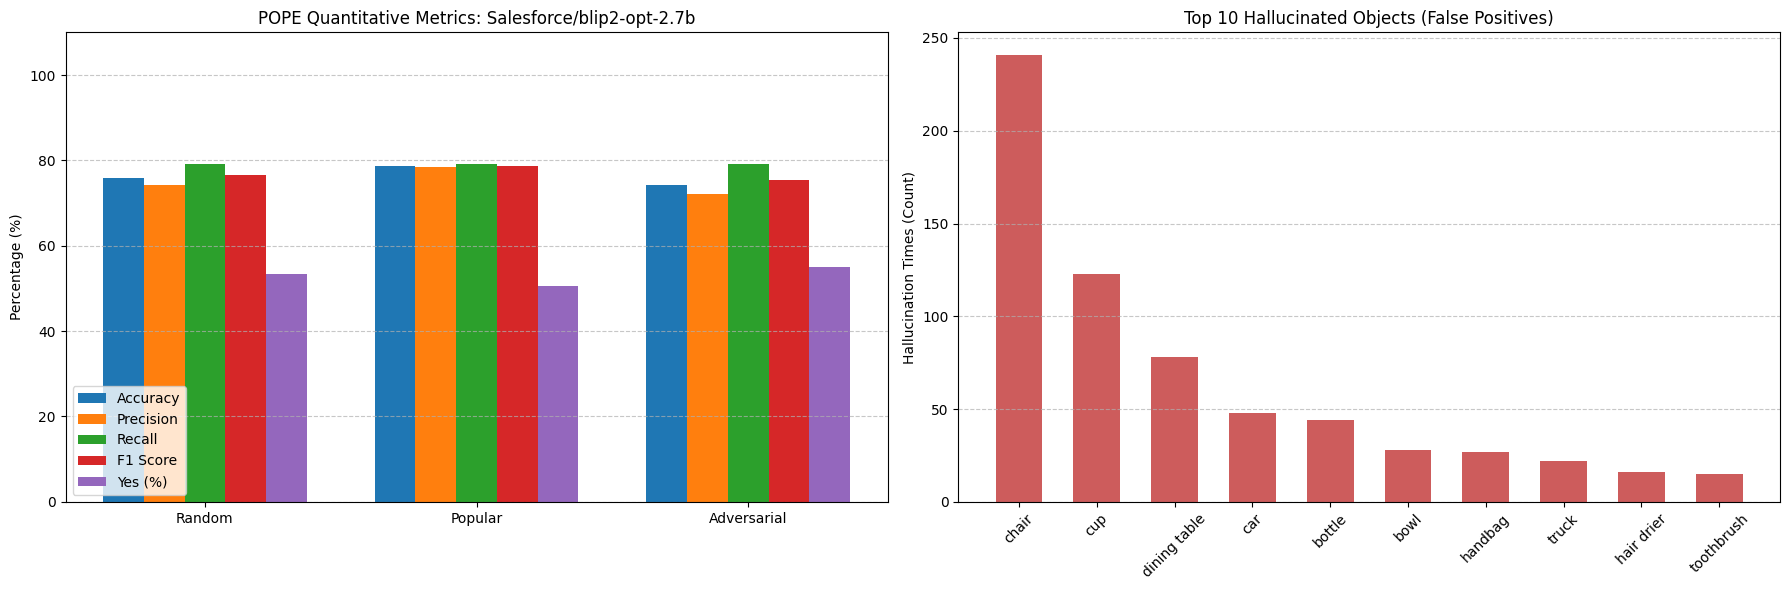

Saved POPE analysis plots to: /kaggle/working/vlm_blip_hallucination/outputs/metrics/pope_analysis_plots.png


In [24]:
# ============================================================
# Visualize POPE Results
# ============================================================

import json
import matplotlib.pyplot as plt
import numpy as np

# Load the POPE results saved in the previous step
with open(POPE_OUT, "r", encoding="utf-8") as f:
    pope_results = json.load(f)

metrics_summary = pope_results["summary"]
top_hallucinated = pope_results.get("top_hallucinated_objects", {})

# Filter out splits to maintain order
splits = ["random", "popular", "adversarial"]
splits = [s for s in splits if s in metrics_summary]

metrics = ["accuracy", "precision", "recall", "f1", "yes_ratio"]
metric_labels = ["Accuracy", "Precision", "Recall", "F1 Score", "Yes (%)"]

fig, ax = plt.subplots(1, 2, figsize=(18, 6))

# ----------------------------------------------------
# 1. Quantitative Metrics Grouped Bar Chart
# ----------------------------------------------------
x = np.arange(len(splits))
width = 0.15
multiplier = 0

for i, metric in enumerate(metrics):
    offset = width * multiplier
    values = [metrics_summary[s][metric] * 100 for s in splits]
    rects = ax[0].bar(x + offset, values, width, label=metric_labels[i])
    multiplier += 1

ax[0].set_ylabel('Percentage (%)')
ax[0].set_title(f'POPE Quantitative Metrics: {MODEL_ID}')
ax[0].set_xticks(x + width * 2)
ax[0].set_xticklabels([s.capitalize() for s in splits])
ax[0].legend(loc='lower left', bbox_to_anchor=(0, 0))
ax[0].set_ylim(0, 110)
ax[0].grid(axis='y', linestyle='--', alpha=0.7)

# ----------------------------------------------------
# 2. Qualitative Hallucination Bar Chart (Paper Fig 2 Style)
# ----------------------------------------------------
if top_hallucinated:
    # Extract top 10 for cleaner visualization
    objects = list(top_hallucinated.keys())[:10]
    counts = list(top_hallucinated.values())[:10]
    
    # Use a distinct color for hallucination times as seen in the paper
    ax[1].bar(objects, counts, color='indianred', width=0.6)
    ax[1].set_ylabel('Hallucination Times (Count)')
    ax[1].set_title('Top 10 Hallucinated Objects (False Positives)')
    ax[1].tick_params(axis='x', rotation=45)
    ax[1].grid(axis='y', linestyle='--', alpha=0.7)
else:
    ax[1].text(0.5, 0.5, "No hallucinations detected.", ha='center', va='center')
    ax[1].set_title('Top Hallucinated Objects')
    ax[1].axis('off')

plt.tight_layout()

# ----------------------------------------------------
# Save and Display
# ----------------------------------------------------
PLOT_OUT = PROJECT / "outputs/metrics/pope_analysis_plots.png"
plt.savefig(PLOT_OUT, dpi=300, bbox_inches='tight')
plt.show()

print(f"Saved POPE analysis plots to: {PLOT_OUT}")

In [25]:
#this will print the details about the model so comment to know the specific input output details of model
#print(type(model))
#print(model)

# HallucinationBench

In [26]:
# ============================================================
# HallusionBench Implementation 
# ============================================================
import os
import json
from collections import defaultdict
from pathlib import Path
from PIL import Image
import torch
from transformers import AutoProcessor, Blip2ForConditionalGeneration, BlipForConditionalGeneration

# Redefine PROJECT
PROJECT = Path("/kaggle/working/vlm_blip_hallucination")

# Check and reload model if the Kaggle kernel was restarted
if "MODEL_ID" not in globals():
    MODEL_ID = "Salesforce/blip2-opt-2.7b"
    device = "cuda" if torch.cuda.is_available() else "cpu"
    dtype = torch.float16 if torch.cuda.is_available() else torch.float32

    print(f"Kernel variables missing. Reloading {MODEL_ID}...")
    try:
        processor = AutoProcessor.from_pretrained(MODEL_ID)
        model = Blip2ForConditionalGeneration.from_pretrained(
            MODEL_ID,
            torch_dtype=dtype,
        ).to(device)
    except Exception as e:
        print("Fallback to BLIP-1:", e)
        MODEL_ID = "Salesforce/blip-image-captioning-large"
        processor = AutoProcessor.from_pretrained(MODEL_ID)
        model = BlipForConditionalGeneration.from_pretrained(
            MODEL_ID,
            torch_dtype=dtype,
        ).to(device)

    model.eval()
# ----------------------------------------------------
# 1. Download and Prepare HallusionBench
# ----------------------------------------------------
HB_DIR = PROJECT / "HallusionBench"
if not HB_DIR.exists():
    print("Cloning HallusionBench repository...")
    !git clone https://github.com/tianyi-lab/HallusionBench.git {HB_DIR}
    # Note: The images are already uncompressed in the 'hallusion_bench' folder 
    # within the repo, so we don't need to run unzip[cite: 27].

with open(HB_DIR / "HallusionBench.json", "r", encoding="utf-8") as f:
    hb_data = json.load(f)

print(f"Loaded {len(hb_data)} visual-question pairs from HallusionBench.")

# ----------------------------------------------------
# 2. Run Inference
# ----------------------------------------------------
hb_results = []
# Create a dummy blank image for "Visual Supplement" questions that have no visual input
blank_image = Image.new('RGB', (224, 224), color=(0, 0, 0)) 

print(f"Evaluating HallusionBench with {MODEL_ID} ...")

for i, row in enumerate(hb_data):
    question = row["question"]
    visual_input = str(row["visual_input"])
    gt_answer = str(row["gt_answer"]) 
    
    if visual_input == "1":
        # lstrip("./") correctly maps "./hallusion_bench/..." format in the JSON to the directory
        img_path = HB_DIR / row["filename"].lstrip("./")
        if not img_path.exists():
            continue
        image = Image.open(img_path).convert("RGB")
    else:
        # No visual condition
        image = blank_image

    prompt = f"Question: {question} Answer:"
    
    inputs = processor(images=image, text=prompt, return_tensors="pt").to(device, dtype)
    
    with torch.inference_mode():
        outputs = model.generate(**inputs, max_new_tokens=5, do_sample=False)
    
    raw_answer = processor.batch_decode(outputs, skip_special_tokens=True)[0].strip().lower()
    
    # Heuristic Answer Parsing
    if "yes" in raw_answer:
        pred = "1"
    elif "no" in raw_answer:
        pred = "0"
    else:
        pred = "2" # Uncertain
        
    # HallusionBench Rule: Uncertain answers are considered acceptable/correct 
    # when there is no visual input under the Visual Supplement category[cite: 27].
    if visual_input == "0" and pred == "2":
        is_correct = 1
    else:
        is_correct = 1 if pred == gt_answer else 0
        
    row_result = row.copy()
    row_result["raw_prediction"] = raw_answer
    row_result["prediction"] = pred
    row_result["is_correct"] = is_correct
    hb_results.append(row_result)

# ----------------------------------------------------
# 3. Compute Specialized Metrics
# ----------------------------------------------------
# All Accuracy (aAcc): Simple global accuracy
aAcc = sum(r["is_correct"] for r in hb_results) / len(hb_results) if hb_results else 0

# Question Pair Accuracy (qAcc): Model must answer all contexts of the same question correctly[cite: 27]
question_groups = defaultdict(list)
for r in hb_results:
    question_groups[r["question"]].append(r["is_correct"])
qAcc = sum(1 for q in question_groups.values() if all(c == 1 for c in q)) / len(question_groups) if question_groups else 0

# Figure Accuracy (fAcc): Model must answer all questions for a specific figure correctly[cite: 27]
figure_groups = defaultdict(list)
for r in hb_results:
    if r["visual_input"] == "1":
        figure_groups[r["filename"]].append(r["is_correct"])
fAcc = sum(1 for f in figure_groups.values() if all(c == 1 for c in f)) / len(figure_groups) if figure_groups else 0

# Yes/No Bias Metrics
total_pred_yes = sum(1 for r in hb_results if r["prediction"] == "1")
total_gt_yes = sum(1 for r in hb_results if r["gt_answer"] == "1")

# Yes Percentage Difference (dy)[cite: 27]
pct_diff = (total_pred_yes - total_gt_yes) / len(hb_results) if hb_results else 0

incorrect_responses = [r for r in hb_results if r["is_correct"] == 0]

# False Positive Ratio (rfp)[cite: 27]
fp_ratio = sum(1 for r in incorrect_responses if r["prediction"] == "1") / len(incorrect_responses) if incorrect_responses else 0

# ----------------------------------------------------
# 4. Display Results
# ----------------------------------------------------
print("\n" + "="*60)
print(f"HALLUSIONBENCH METRICS : {MODEL_ID}")
print("="*60)
print(f"All Accuracy (aAcc)             : {aAcc*100:.2f}%")
print(f"Question Pair Accuracy (qAcc)   : {qAcc*100:.2f}%")
print(f"Figure Accuracy (fAcc)          : {fAcc*100:.2f}%")
print("-" * 60)
print(f"Yes Pct. Difference (dy)        : {pct_diff:.3f}  (Ideal ~ 0.0)")
print(f"False Positive Ratio (rfp)      : {fp_ratio:.3f}  (Ideal ~ 0.5)")
print("="*60)

# Save results
HB_OUT = PROJECT / "outputs/metrics/hallusionbench_results.json"
HB_OUT.parent.mkdir(parents=True, exist_ok=True)
with open(HB_OUT, "w") as f:
    json.dump({
        "metrics": {"aAcc": aAcc, "qAcc": qAcc, "fAcc": fAcc, "pct_diff": pct_diff, "fp_ratio": fp_ratio}, 
        "results": hb_results
    }, f, indent=2)

Loaded 1129 visual-question pairs from HallusionBench.
Evaluating HallusionBench with Salesforce/blip2-opt-2.7b ...

HALLUSIONBENCH METRICS : Salesforce/blip2-opt-2.7b
All Accuracy (aAcc)             : 41.94%
Question Pair Accuracy (qAcc)   : 41.15%
Figure Accuracy (fAcc)          : 0.00%
------------------------------------------------------------
Yes Pct. Difference (dy)        : 0.019  (Ideal ~ 0.0)
False Positive Ratio (rfp)      : 0.460  (Ideal ~ 0.5)


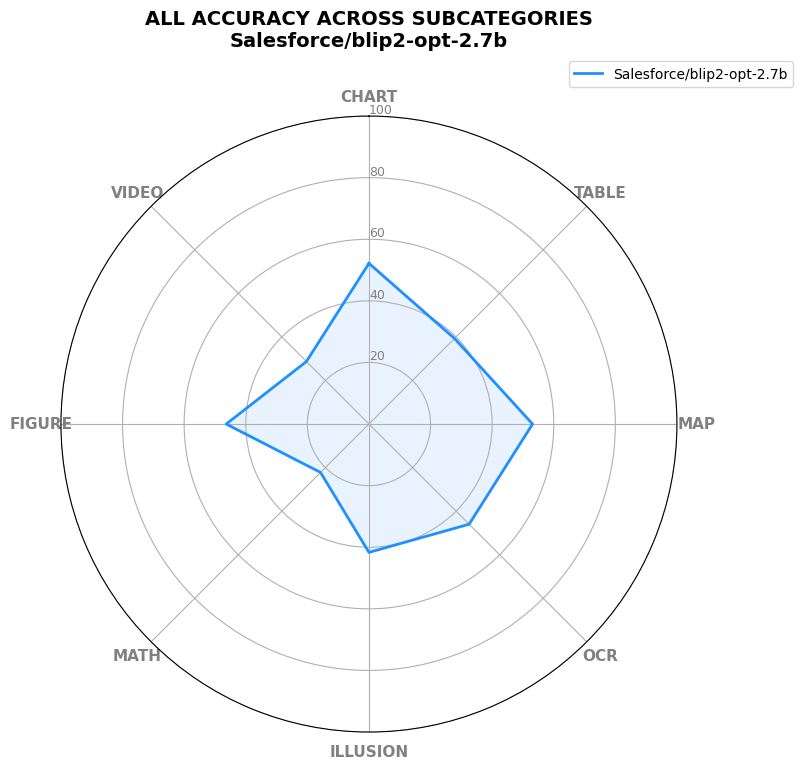

Saved Radar Chart to: /kaggle/working/vlm_blip_hallucination/outputs/metrics/hallusionbench_radar.png


In [27]:
# ============================================================
# HallusionBench Radar Chart (Paper Figure 4 Style)
# ============================================================
import json
import numpy as np
import matplotlib.pyplot as plt
from math import pi
from pathlib import Path

# Reload results if necessary
HB_OUT = Path("/kaggle/working/vlm_blip_hallucination/outputs/metrics/hallusionbench_results.json")
with open(HB_OUT, "r", encoding="utf-8") as f:
    hb_data = json.load(f)

hb_results = hb_data["results"]

# 1. Extract and Aggregate Accuracy per Subcategory
subcategory_stats = {}

for r in hb_results:
    # Safely extract subcategory directly from the JSON, defaulting to "OTHER"
    subcat = r.get("subcategory")
    if not subcat:
        subcat = "other"
    subcat = subcat.upper()
    
    if subcat not in subcategory_stats:
        subcategory_stats[subcat] = {"correct": 0, "total": 0}
        
    subcategory_stats[subcat]["total"] += 1
    subcategory_stats[subcat]["correct"] += r["is_correct"]

# Prepare data for plotting
categories = list(subcategory_stats.keys())
accuracies = [(subcategory_stats[c]["correct"] / subcategory_stats[c]["total"]) * 100 for c in categories]

# 2. Radar Chart Setup
N = len(categories)
angles = [n / float(N) * 2 * pi for n in range(N)]

# Complete the loop so the polygon closes
categories += categories[:1]
accuracies += accuracies[:1]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

# Rotate chart so the first axis is at the top
ax.set_theta_offset(pi / 2)
ax.set_theta_direction(-1)

# Draw y-axis labels
plt.xticks(angles[:-1], categories[:-1], color='grey', size=11, fontweight='bold')
ax.set_rlabel_position(0)
plt.yticks([20, 40, 60, 80, 100], ["20", "40", "60", "80", "100"], color="grey", size=9)
plt.ylim(0, 100)

# 3. Plot the Data
# Ensure MODEL_ID is defined (fallback to "BLIP-2" if not in globals)
current_model = globals().get("MODEL_ID", "BLIP-2")

ax.plot(angles, accuracies, linewidth=2, linestyle='solid', color='dodgerblue', label=current_model)
ax.fill(angles, accuracies, 'dodgerblue', alpha=0.1)

plt.title(f'ALL ACCURACY ACROSS SUBCATEGORIES\n{current_model}', size=14, fontweight='bold', y=1.1)
plt.legend(loc='upper right', bbox_to_anchor=(1.2, 1.1))

# Save and Display
RADAR_OUT = Path("/kaggle/working/vlm_blip_hallucination/outputs/metrics/hallusionbench_radar.png")
plt.savefig(RADAR_OUT, dpi=300, bbox_inches='tight')
plt.show()

print(f"Saved Radar Chart to: {RADAR_OUT}")

# THRONE 


In [28]:
# ============================================================
# Batched THRONE Benchmark (500 Images x 80 Classes = 40,000 Queries)
# ============================================================
import os
import re
import json
from pathlib import Path
from PIL import Image
import torch
import numpy as np
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from tqdm.auto import tqdm

THRONE_OUT = PROJECT / "outputs/metrics/throne_results_500.json"
FREEFORM_OUT = PROJECT / "outputs/captions/blip_detailed_descriptions_500.jsonl"
FREEFORM_OUT.parent.mkdir(parents=True, exist_ok=True)

with open(SUBSET_MANIFEST_PATH, "r", encoding="utf-8") as f:
    subset_manifest = json.load(f)

cat_id_to_name = {c["id"]: c["name"] for c in instances["categories"]}
coco_categories = sorted(list(set(cat_id_to_name.values())))
cat_to_idx = {cat: i for i, cat in enumerate(coco_categories)}
num_classes = len(coco_categories)

# Build ground-truth binary existence matrix from instances
gt_inst_map = {}
for ann in instances["annotations"]:
    img_id = int(ann["image_id"])
    gt_inst_map.setdefault(img_id, set()).add(cat_id_to_name[int(ann["category_id"])])

# 1. Generate Free-Form Detailed Descriptions for 500 Images in Batches
prompt_text = "Question: Describe this image in detail. Answer:"
descriptions = []

desc_dataset = COCOCaptionDataset(subset_manifest["images"], COCO_IMG_DIR)
desc_loader = DataLoader(
    desc_dataset, batch_size=64, shuffle=False, num_workers=2, collate_fn=collate_pil, pin_memory=True
)

print(f"Generating free-form descriptions for {len(desc_dataset)} images using {MODEL_ID}...")
with open(FREEFORM_OUT, "w", encoding="utf-8") as fout:
    for batch_imgs, batch_ids, batch_files in tqdm(desc_loader, desc="BLIP-2 Free-Form Gen"):
        batch_prompts = [prompt_text] * len(batch_imgs)
        inputs = processor(images=batch_imgs, text=batch_prompts, return_tensors="pt", padding=True).to(device, dtype)
        input_len = inputs["input_ids"].shape[1]
        
        with torch.inference_mode():
            out_ids = model.generate(**inputs, max_new_tokens=100, do_sample=False)
        
        new_tokens = out_ids[:, input_len:]
        decoded_batch = processor.batch_decode(new_tokens, skip_special_tokens=True)
        
        for img_id, fname, text_desc in zip(batch_ids, batch_files, decoded_batch):
            clean_desc = re.sub(r"^question:.*?answer:\s*", "", text_desc.strip(), flags=re.IGNORECASE).strip()
            record = {
                "image_id": int(img_id),
                "file_name": fname,
                "description": clean_desc
            }
            descriptions.append(record)
            fout.write(json.dumps(record, ensure_ascii=False) + "\n")

num_images = len(descriptions)
print(f"Generated {num_images} descriptions. Sample: {descriptions[0]['description']}")

# 2. Load FLAN-T5-Base for Abstractive QA (AQA)
AQA_MODEL_ID = "google/flan-t5-base"
print(f"\nLoading AQA Model: {AQA_MODEL_ID}...")
aqa_tokenizer = AutoTokenizer.from_pretrained(AQA_MODEL_ID)
aqa_model = AutoModelForSeq2SeqLM.from_pretrained(AQA_MODEL_ID, torch_dtype=dtype).to(device)
aqa_model.eval()

# 3. Batched AQA over all 40,000 (Image, Class) pairs
aqa_queries = []
query_metadata = []

for img_idx, rec in enumerate(descriptions):
    desc = rec["description"]
    for class_idx, cat in enumerate(coco_categories):
        prompt_aqa = (
            f"Text: {desc} Read the text about an image and answer the question.\n"
            f"Question: Please answer yes or no. Is there a {cat} in this image?"
        )
        aqa_queries.append(prompt_aqa)
        query_metadata.append((img_idx, class_idx))

print(f"Evaluating {len(aqa_queries)} AQA queries ({num_images} images x {num_classes} classes)...")

AQA_BATCH_SIZE = 256
predictions_flat = []

for i in tqdm(range(0, len(aqa_queries), AQA_BATCH_SIZE), desc="FLAN-T5 AQA"):
    batch_texts = aqa_queries[i:i + AQA_BATCH_SIZE]
    inputs = aqa_tokenizer(
        batch_texts, return_tensors="pt", padding=True, truncation=True, max_length=256
    ).to(device)
    
    with torch.inference_mode():
        outputs = aqa_model.generate(**inputs, max_new_tokens=4, do_sample=False)
    
    decoded = aqa_tokenizer.batch_decode(outputs, skip_special_tokens=True)
    for ans in decoded:
        predictions_flat.append(1 if "yes" in ans.strip().lower() else 0)

# Free FLAN-T5 VRAM after completion
del aqa_model
torch.cuda.empty_cache()

# 4. Compute THRONE Metrics (Kaul et al., CVPR 2024)
Y = np.zeros((num_images, num_classes), dtype=int)
Y_hat = np.zeros((num_images, num_classes), dtype=int)

for img_idx, rec in enumerate(descriptions):
    for obj in gt_inst_map.get(rec["image_id"], set()):
        if obj in cat_to_idx:
            Y[img_idx, cat_to_idx[obj]] = 1

for (img_idx, class_idx), pred in zip(query_metadata, predictions_flat):
    Y_hat[img_idx, class_idx] = pred

def calc_f_score(p, r, beta=0.5):
    return (1 + beta**2) * (p * r) / (beta**2 * p + r) if (beta**2 * p + r) > 0 else 0.0

tp_all = int(np.sum((Y == 1) & (Y_hat == 1)))
fp_all = int(np.sum((Y == 0) & (Y_hat == 1)))
fn_all = int(np.sum((Y == 1) & (Y_hat == 0)))

p_all = tp_all / (tp_all + fp_all) if (tp_all + fp_all) > 0 else 0.0
r_all = tp_all / (tp_all + fn_all) if (tp_all + fn_all) > 0 else 0.0
f1_all = calc_f_score(p_all, r_all, beta=1.0)
f05_all = calc_f_score(p_all, r_all, beta=0.5)

p_cls_list, r_cls_list = [], []
for c in range(num_classes):
    tp_c = np.sum((Y[:, c] == 1) & (Y_hat[:, c] == 1))
    fp_c = np.sum((Y[:, c] == 0) & (Y_hat[:, c] == 1))
    fn_c = np.sum((Y[:, c] == 1) & (Y_hat[:, c] == 0))
    if (tp_c + fn_c) > 0:  # Only average over classes present in ground truth
        p_c = tp_c / (tp_c + fp_c) if (tp_c + fp_c) > 0 else 0.0
        r_c = tp_c / (tp_c + fn_c)
        p_cls_list.append(p_c)
        r_cls_list.append(r_c)

p_cls = float(np.mean(p_cls_list))
r_cls = float(np.mean(r_cls_list))
f1_cls = calc_f_score(p_cls, r_cls, beta=1.0)
f05_cls = calc_f_score(p_cls, r_cls, beta=0.5)
median_length = int(np.median([len(r["description"]) for r in descriptions]))

throne_summary = {
    "model": MODEL_ID,
    "aqa_model": AQA_MODEL_ID,
    "num_images": num_images,
    "median_char_length": median_length,
    "overall_metrics": {
        "P_ALL": round(p_all * 100, 2), "R_ALL": round(r_all * 100, 2),
        "F1_ALL": round(f1_all * 100, 2), "F05_ALL": round(f05_all * 100, 2)
    },
    "classwise_metrics": {
        "P_CLS": round(p_cls * 100, 2), "R_CLS": round(r_cls * 100, 2),
        "F1_CLS": round(f1_cls * 100, 2), "F05_CLS": round(f05_cls * 100, 2)
    }
}

with open(THRONE_OUT, "w", encoding="utf-8") as f:
    json.dump({"summary": throne_summary, "descriptions": descriptions}, f, indent=2)

print("\n" + "=" * 80)
print(f"THRONE TYPE-I HALLUCINATION BENCHMARK (500 IMAGES) : {MODEL_ID}")
print("=" * 80)
print(f"Median Description Length (L) : {median_length} chars")
print("-" * 80)
print(f"{'Metric Type':18s} | {'Precision (P)':>14s} | {'Recall (R)':>12s} | {'F1-Score':>10s} | {'F0.5-Score':>12s}")
print("-" * 80)
print(f"{'Overall (ALL)':18s} | {p_all * 100:13.2f}% | {r_all * 100:11.2f}% | {f1_all * 100:9.2f}% | {f05_all * 100:11.2f}%")
print(f"{'Class-wise (CLS)':18s} | {p_cls * 100:13.2f}% | {r_cls * 100:11.2f}% | {f1_cls * 100:9.2f}% | {f05_cls * 100:11.2f}%*")
print("=" * 80)

Generating free-form descriptions for 500 images using Salesforce/blip2-opt-2.7b...


BLIP-2 Free-Form Gen:   0%|          | 0/8 [00:00<?, ?it/s]

Generated 500 descriptions. Sample: A stop sign on a street corner

Loading AQA Model: google/flan-t5-base...


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

Evaluating 40000 AQA queries (500 images x 80 classes)...


FLAN-T5 AQA:   0%|          | 0/157 [00:00<?, ?it/s]


THRONE TYPE-I HALLUCINATION BENCHMARK (500 IMAGES) : Salesforce/blip2-opt-2.7b
Median Description Length (L) : 37 chars
--------------------------------------------------------------------------------
Metric Type        |  Precision (P) |   Recall (R) |   F1-Score |   F0.5-Score
--------------------------------------------------------------------------------
Overall (ALL)      |         58.43% |       56.81% |     57.61% |       58.10%
Class-wise (CLS)   |         67.16% |       58.89% |     62.75% |       65.32%*


In [29]:
# ============================================================
#  Vectorized Batched POPE with Visual Contrastive Decoding (VCD)
# Fixes FP16 underflow (T=500, gamma=0.005) & batches [B clean + B noisy]
# ============================================================
import json
import torch
import numpy as np
from PIL import Image
from transformers import LogitsProcessor, LogitsProcessorList
from tqdm.auto import tqdm

def add_diffusion_noise(image_tensor, steps=500, gamma=0.005):
    """
    Applies forward diffusion Gaussian noise without FP16 underflow.
    At T=500, gamma=0.005 -> sqrt(alpha_bar) = 0.286 (28.6% signal, 95.8% noise).
    """
    alpha_bar = (1.0 - gamma) ** steps
    sqrt_alpha_bar = float(alpha_bar ** 0.5)
    sqrt_one_minus_alpha_bar = float((1.0 - alpha_bar) ** 0.5)
    
    noise = torch.randn_like(image_tensor)
    distorted = sqrt_alpha_bar * image_tensor + sqrt_one_minus_alpha_bar * noise
    return distorted.to(dtype=image_tensor.dtype)

class BatchedVCDLogitsProcessor(LogitsProcessor):
    def __init__(self, alpha=1.0, beta=0.1):
        self.alpha = alpha
        self.beta = beta

    def __call__(self, input_ids: torch.LongTensor, scores: torch.FloatTensor) -> torch.FloatTensor:
        # First half of batch [:B] is clean image; second half [B:] is noisy image
        B = scores.shape[0] // 2
        logits_orig = scores[:B].float()
        logits_dist = scores[B:].float()
        
        # Adaptive Plausibility Constraint (APC) per batch item
        probs_orig = torch.softmax(logits_orig, dim=-1)
        max_prob = torch.max(probs_orig, dim=-1, keepdim=True).values
        valid_mask = probs_orig >= (self.beta * max_prob)
        
        # Visual Contrastive Logits: (1 + alpha) * l_orig - alpha * l_dist
        vcd_logits = (1.0 + self.alpha) * logits_orig - self.alpha * logits_dist
        vcd_logits = vcd_logits.masked_fill(~valid_mask, -float("inf"))
        
        vcd_out = vcd_logits.to(dtype=scores.dtype)
        scores[:B] = vcd_out
        scores[B:] = vcd_out
        return scores

POPE_VCD_OUT = PROJECT / "outputs/metrics/blip_pope_vcd_results.json"

# Use batch_size=32 because each batch processes 32 clean + 32 noisy = 64 images
VCD_BATCH_SIZE = 32
vcd_loader = DataLoader(
    POPEQueryDataset(unique_query_list, COCO_IMG_DIR),
    batch_size=VCD_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_pope,
    pin_memory=True
)

vcd_processor = BatchedVCDLogitsProcessor(alpha=1.0, beta=0.1)
logits_processor_list = LogitsProcessorList([vcd_processor])

vcd_cache = {}
torch.manual_seed(42)

print(f"Evaluating {len(unique_query_list)} unique POPE queries with VCD (T=500, gamma=0.005, alpha=1.0, beta=0.1)...")

for batch_imgs, batch_prompts, batch_ids, batch_qs in tqdm(vcd_loader, desc="Running Batched VCD"):
    inputs = processor(
        images=batch_imgs,
        text=batch_prompts,
        return_tensors="pt",
        padding=True
    ).to(device, dtype)
    
    B = inputs["pixel_values"].shape[0]
    input_len = inputs["input_ids"].shape[1]
    
    orig_pixel = inputs["pixel_values"]
    dist_pixel = add_diffusion_noise(orig_pixel, steps=500, gamma=0.005)
    
    batched_inputs = {
        "pixel_values": torch.cat([orig_pixel, dist_pixel], dim=0),
        "input_ids": inputs["input_ids"].repeat(2, 1),
        "attention_mask": inputs["attention_mask"].repeat(2, 1)
    }

    with torch.inference_mode():
        outputs = model.generate(
            **batched_inputs,
            max_new_tokens=4,
            do_sample=False,
            logits_processor=logits_processor_list
        )

    # Slice off prompt tokens for the first B sequences
    new_tokens = outputs[:B, input_len:]
    decoded_answers = processor.batch_decode(new_tokens, skip_special_tokens=True)

    for img_id, q_text, raw_ans in zip(batch_ids, batch_qs, decoded_answers):
        clean_ans = raw_ans.strip().lower()
        if "yes" in clean_ans:
            pred = "yes"
        elif "no" in clean_ans:
            pred = "no"
        else:
            pred = "unknown"
        vcd_cache[(int(img_id), q_text)] = pred

# Aggregate VCD Metrics Across Splits
vcd_split_stats = {
    "random": {"tp": 0, "tn": 0, "fp": 0, "fn": 0},
    "popular": {"tp": 0, "tn": 0, "fp": 0, "fn": 0},
    "adversarial": {"tp": 0, "tn": 0, "fp": 0, "fn": 0}
}
pope_vcd_records = []

for q in pope_questions:
    pred = vcd_cache[(q["image_id"], q["question"])]
    gt = q["answer"]
    split = q["split"]

    pope_vcd_records.append({
        "image_id": q["image_id"],
        "split": split,
        "object": q["object"],
        "question": q["question"],
        "ground_truth": gt,
        "prediction": pred,
        "correct": pred == gt
    })

    if gt == "yes":
        if pred == "yes":
            vcd_split_stats[split]["tp"] += 1
        else:
            vcd_split_stats[split]["fn"] += 1
    else:
        if pred == "yes":
            vcd_split_stats[split]["fp"] += 1
        elif pred == "no":
            vcd_split_stats[split]["tn"] += 1

vcd_metrics_summary = {}
print("\n" + "=" * 80)
print(f"POPE WITH VCD RESULTS (T=500, gamma=0.005) : {MODEL_ID}")
print("=" * 80)
print(f"{'SPLIT':12s} | {'Accuracy':>8s} | {'Precision':>9s} | {'Recall':>8s} | {'F1 Score':>8s} | {'Yes (%)':>8s}")
print("-" * 80)

for split, s in vcd_split_stats.items():
    tp, tn, fp, fn = s["tp"], s["tn"], s["fp"], s["fn"]
    total = tp + tn + fp + fn
    acc = (tp + tn) / total if total else 0.0
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = (2 * prec * rec / (prec + rec)) if (prec + rec) else 0.0
    yes_ratio = (tp + fp) / total if total else 0.0

    vcd_metrics_summary[split] = {
        "accuracy": acc, "precision": prec, "recall": rec, "f1": f1, "yes_ratio": yes_ratio
    }
    print(f"{split.capitalize():12s} | {acc*100:7.2f}% | {prec*100:8.2f}% | {rec*100:7.2f}% | {f1*100:7.2f}% | {yes_ratio*100:7.2f}%")
print("=" * 80)

with open(POPE_VCD_OUT, "w", encoding="utf-8") as f:
    json.dump({"summary": vcd_metrics_summary, "results": pope_vcd_records}, f, indent=2)

Evaluating 3858 unique POPE queries with VCD (T=500, gamma=0.005, alpha=1.0, beta=0.1)...


Running Batched VCD:   0%|          | 0/121 [00:00<?, ?it/s]


POPE WITH VCD RESULTS (T=500, gamma=0.005) : Salesforce/blip2-opt-2.7b
SPLIT        | Accuracy | Precision |   Recall | F1 Score |  Yes (%)
--------------------------------------------------------------------------------
Random       |   74.11% |    71.81% |   79.42% |   75.43% |   55.32%
Popular      |   78.10% |    77.37% |   79.42% |   78.38% |   51.32%
Adversarial  |   74.24% |    71.98% |   79.42% |   75.52% |   55.19%


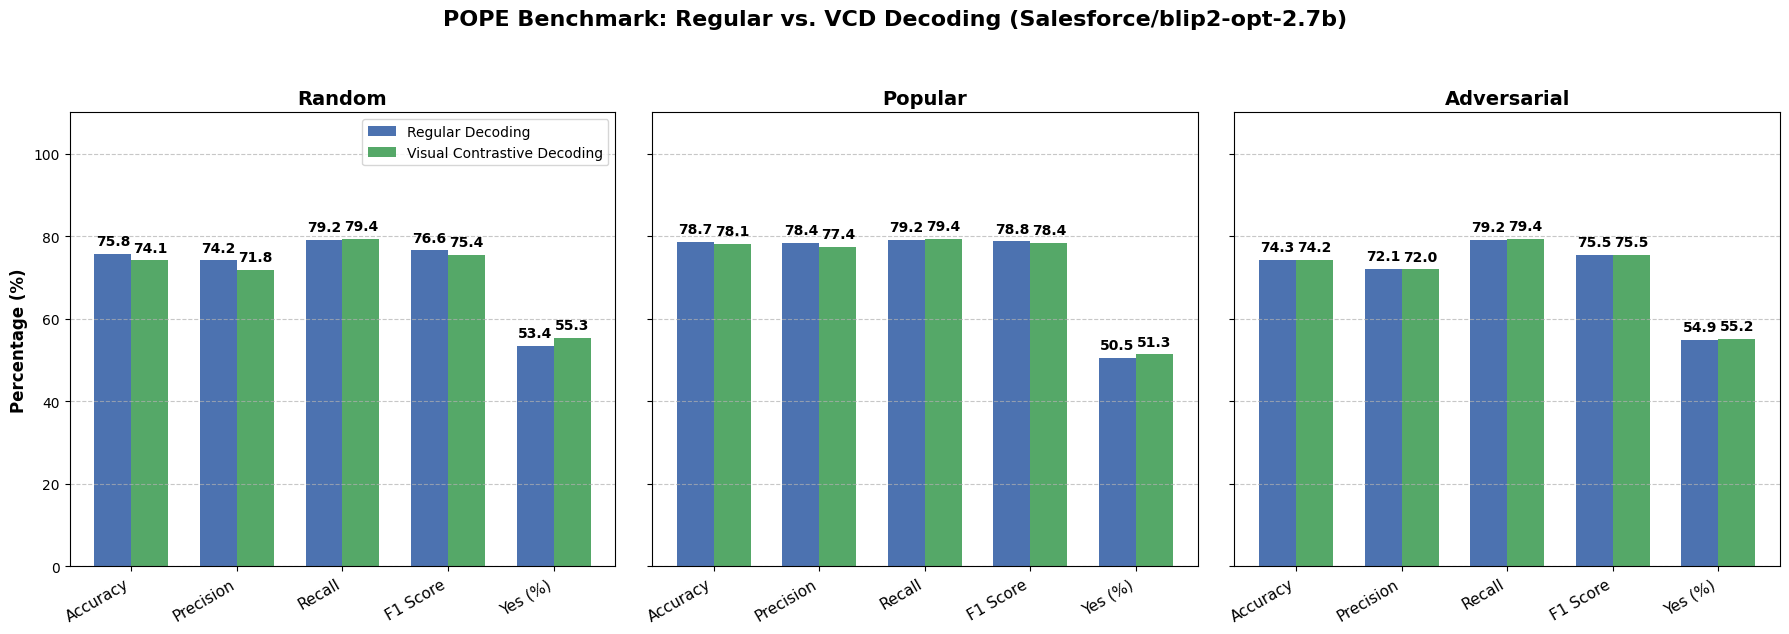

Saved Regular vs VCD POPE comparison chart to: /kaggle/working/vlm_blip_hallucination/outputs/metrics/pope_vcd_comparison.png


In [30]:
# ============================================================
# Visualize POPE Benchmark (Regular vs VCD)
# ============================================================
import json
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Paths to the previously saved results
POPE_OUT = PROJECT / "outputs/metrics/blip_pope_results.json"
POPE_VCD_OUT = PROJECT / "outputs/metrics/blip_pope_vcd_results.json"

# Load the baseline (without VCD) and VCD data directly from disk
with open(POPE_OUT, "r", encoding="utf-8") as f:
    base_data = json.load(f)["summary"]

with open(POPE_VCD_OUT, "r", encoding="utf-8") as f:
    vcd_data = json.load(f)["summary"]

splits = ["random", "popular", "adversarial"]
metrics = ["accuracy", "precision", "recall", "f1", "yes_ratio"]
metric_labels = ["Accuracy", "Precision", "Recall", "F1 Score", "Yes (%)"]

# Create a 1x3 grid of subplots for each POPE split
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
fig.suptitle(f"POPE Benchmark: Regular vs. VCD Decoding ({MODEL_ID})", fontsize=16, fontweight="bold", y=1.05)

x = np.arange(len(metrics))
width = 0.35

for i, split in enumerate(splits):
    ax = axes[i]
    
    # Extract the percentage values for baseline and VCD
    base_vals = [base_data[split][m] * 100 for m in metrics]
    vcd_vals = [vcd_data[split][m] * 100 for m in metrics]
    
    # Plot grouped bars
    rects1 = ax.bar(x - width/2, base_vals, width, label="Regular Decoding", color="#4C72B0")
    rects2 = ax.bar(x + width/2, vcd_vals, width, label="Visual Contrastive Decoding", color="#55A868")
    
    ax.set_title(split.capitalize(), fontsize=14, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(metric_labels, rotation=30, ha="right", fontsize=11)
    ax.set_ylim(0, 110)
    ax.grid(axis="y", linestyle="--", alpha=0.7)
    
    # Add numerical labels on top of each bar
    for rect in rects1 + rects2:
        height = rect.get_height()
        ax.annotate(f"{height:.1f}",
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 4),  # 4 points vertical offset
                    textcoords="offset points",
                    ha="center", va="bottom", fontsize=10, fontweight="bold")
    
    # Only add the Y-axis label and Legend to the first subplot to keep it clean
    if i == 0:
        ax.set_ylabel("Percentage (%)", fontsize=12, fontweight="bold")
        ax.legend(loc="upper right")

plt.tight_layout()

# Save and show the plot
PLOT_OUT = PROJECT / "outputs/metrics/pope_vcd_comparison.png"
plt.savefig(PLOT_OUT, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved Regular vs VCD POPE comparison chart to: {PLOT_OUT}")

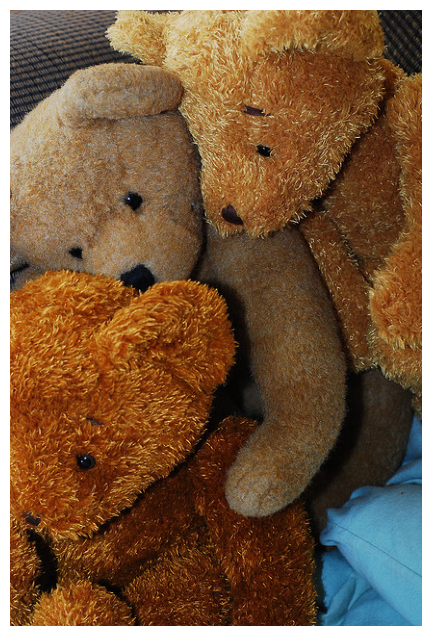

DECODED: Question:This is photo of three teddy bears sitting on a bed



In [54]:
from PIL import Image
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

sample_row = full_manifest["images"][4]#Change here to change the image 
image_path = COCO_IMG_DIR / sample_row["file_name"]
img = Image.open(image_path).convert("RGB")

prompt = "Question:This is photo of"
# for captioning, you can also try:
# prompt = "A photo of"

plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.axis("off")
plt.show()

inputs = processor(images=img, text=prompt, return_tensors="pt")

# move everything to the model device properly
inputs = {k: v.to(model.device) for k, v in inputs.items()}

with torch.no_grad():
    out_ids = model.generate(
        **inputs,
        max_new_tokens=30,
        do_sample=False,
        num_beams=3
    )

#print("RAW IDS:", out_ids)
print("DECODED:", processor.batch_decode(out_ids, skip_special_tokens=True)[0])

In [56]:
from PIL import Image
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

sample_row = full_manifest["images"][4]#Change here to change the Image
image_path = COCO_IMG_DIR / sample_row["file_name"]
img = Image.open(image_path).convert("RGB")

prompt = "Question: Is there a bed in the image? Answer:"#Change here to change the prompt 
inputs = processor(images=img, text=prompt, return_tensors="pt")
inputs = {k: v.to(model.device) for k, v in inputs.items()}

with torch.no_grad():
    out_ids = model.generate(**inputs, max_new_tokens=5, do_sample=False)

decoded = processor.batch_decode(out_ids, skip_special_tokens=True)[0]

if decoded.startswith(prompt):
    answer = decoded[len(prompt):].strip()
else:
    answer = decoded.strip()

print("DECODED:", decoded)
print("ANSWER:", answer)

DECODED: Question: Is there a bed in the image? Answer: Yes

ANSWER: Yes


In [ ]:
# change the number in the [] to change the image